<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 02 · Machine Learning: fundamentos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">02 · CRISP-DM: sobrevivência no Titanic</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Que tipo de pessoa sobrevive?</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/02-machine-learning-fundamentals/blob/main/01_supervised_learning/notebooks/02_CRISP-DM_Titanic_Survival.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_02-ffd43b)](https://the-ai-learning-hub.github.io/02-machine-learning-fundamentals/#metricas)

## 🎯 Objetivos de aprendizagem
Ao terminares este notebook, vais conseguir:

- percorrer as **6 fases do CRISP-DM** num problema de **classificação** (1309 passageiros do Titanic);
- explorar taxas de sobrevivência por sexo, classe, idade e família, e ver interações (**classe × sexo**);
- tratar valores em falta **dentro do *pipeline*** (idade por mediana do título) e criar variáveis úteis (`title`, `family_size`, `deck`);
- reconhecer e demonstrar ***data leakage*** (`boat`, `body`): uma accuracy de 0,966 que **não vale nada**;
- avaliar um classificador com accuracy, *precision*, *recall*, F1, curvas ROC e PR, e matriz de confusão;
- escolher um **threshold** a partir de **custos** de erro, com probabilidades *out-of-fold*, e discutir **ética e equidade**.

**⏱️ Duração estimada:** ≈ 45 min · **📋 Pré-requisitos:** Notebook 01 (CRISP-DM nas casas) ou noções de treino/teste · **▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [🧭 Business Understanding (compreensão do negócio)](#sec-1)
2. [🔎 Data Understanding (compreensão dos dados)](#sec-2)
3. [🧹 Data Preparation (preparação dos dados)](#sec-3)
4. [🚨 Leakage: quando a accuracy mente](#sec-4)
5. [🤖 Modeling (modelação)](#sec-5)
6. [📏 Evaluation (avaliação)](#sec-6)
7. [🚀 Deployment (implementação)](#sec-7)
8. [📌 Resumo](#sec-8)
9. [📚 Para saber mais](#sec-9)

<a id="sec-0"></a>
## ⚙️ Preparar o ambiente

In [1]:
# ⚙️ Preparar o ambiente: funciona localmente (VS Code/Jupyter) e no Google Colab
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/02-machine-learning-fundamentals")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/02-machine-learning-fundamentals.git",
                        str(ROOT)], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

try:  # o Colab já traz tudo; localmente usa `uv sync` (ver README)
    import sklearn, seaborn  # noqa: F401
except ImportError:  # plano B: instala as dependências declaradas no pyproject.toml
    import tomllib
    deps = tomllib.loads((ROOT / "pyproject.toml").read_text(encoding="utf-8"))["project"]["dependencies"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *deps], check=True)

sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Raiz do projeto: 02-machine-learning-fundamentals (local)


> 🗺️ **Recordar o fio condutor.** CRISP-DM: **Business Understanding** (compreensão do negócio) → **Data Understanding** (compreensão dos dados) → **Data Preparation** (preparação dos dados) → **Modeling** (modelação) → **Evaluation** (avaliação) → **Deployment** (implementação). No notebook 01 previmos um **número** (regressão); aqui prevemos uma **categoria** (sobrevive / não sobrevive): **classificação**, onde as métricas e os tipos de erro mudam.

> 📖 **Vocabulário básico** (dataset, linha, *feature*, alvo, modelo, treinar, prever, erro, *baseline*, *overfitting*): ver o [📖 Vocabulário do notebook 01](01_CRISP-DM_House_Prices.ipynb#vocab). **Novos termos aqui:**
> - **Classificação**: prever uma **categoria** (sobrevive / não sobrevive) em vez de um número.
> - **Probabilidade**: o modelo diz "72 % de hipóteses de sobreviver"; **decidimos** depois com um limite.
> - ***Threshold* (limiar)**: a probabilidade mínima a partir da qual dizemos "sobrevive" (por omissão 0,5).
> - **Estratificado**: dividir os dados mantendo a mesma proporção de sobreviventes em cada parte.
> - ***Leakage* (fuga)**: usar informação que só se conhece depois do desfecho (secção 4).

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.data import load_titanic
from src.metrics import best_threshold, confusion_at, threshold_table
from matplotlib.ticker import MultipleLocator
from src.plotting import MARKERS, PALETTE, apply_style, fmt_pt, label_bars, pt_axis
from src.preprocessing import (TITANIC_CATEGORICAL, TITANIC_FEATURES, TITANIC_NUMERIC, GroupMedianImputer,
                               add_titanic_features, make_titanic_preprocessor)

apply_style()
PT_VARS = {"age": "idade", "fare": "tarifa", "sibsp": "irmãos/cônjuge", "parch": "pais/filhos", "family_size": "tamanho da família",
           "pclass": "classe", "sex": "sexo", "embarked": "porto", "title": "título", "deck": "convés", "is_alone": "viaja sozinho"}
def fmt_sgn(v, d=0):
    """Número com sinal explícito, em formato PT."""
    return ("+" if v >= 0 else "−") + fmt_pt(abs(v), d)
print("Pronto.")

Pronto.


<a id="sec-1"></a>
# 1. 🧭 Business Understanding (compreensão do negócio)

### O contexto
Na noite de **14 para 15 de abril de 1912**, o RMS *Titanic* bateu num icebergue no Atlântico Norte e afundou-se. Morreram mais de **1 500** pessoas. Os botes salva-vidas não chegavam para todos e vigorou o princípio **"mulheres e crianças primeiro"**. Os dados que vamos usar (`titanic3`, Harrell & Cason) descrevem 1309 passageiros.

> ⚠️ **Cuidado com o tom:** são **pessoas reais**. Usamos o Titanic porque é um exemplo clássico e limpo, não para "gamificar" uma tragédia. As regras que descobrirmos descrevem **escolhas sociais de 1912** (quem teve acesso a botes), não "traços" das pessoas.

### Que pergunta de negócio?
*"Que tipo de pessoa sobrevive?"* É uma pergunta **descritiva**: queremos perceber que fatores se associam à sobrevivência e construir um modelo que estime a probabilidade. Mas um modelo é sempre **para alguém, para decidir algo**. Dois cenários possíveis, com custos de erro muito diferentes:

| Cenário | Decisão | Erro mais caro |
|---|---|---|
| 📚 **Historiador** | Perceber que grupos tiveram menos acesso a botes | Nenhum especial: interessa a interpretação |
| 🚑 **Equipa de socorro** *(cenário didático, custos inventados para o exemplo)* | Decidir quem **não** precisa de ajuda prioritária | Dizer "sobrevive" a quem não sobrevive (falso positivo) custa **5**; o contrário custa **1** |

Vamos voltar ao segundo na avaliação, para ver como o **custo do erro** muda o *threshold* (limiar de decisão).

### 💬 Discussão — O que é um modelo "bom" aqui?
Se 38 % dos passageiros sobreviveram, um "modelo" que diz sempre "morre" acerta em 62 %. Quando é que uma accuracy de 80 % seria uma má notícia?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

O **baseline** da classe maioritária dá accuracy **0,618** (mais adiante vamos medi-lo): qualquer modelo tem de o bater com folga. Um 80 % não é "bom" nem "mau" em abstrato: é **+18 pontos** acima do baseline, mas pode esconder um *recall* baixo na classe que mais importa (quem sobrevive/quem precisa de ajuda). A accuracy trata todos os erros por igual; no cenário de socorro um falso positivo custa 5× mais. Por isso definimos primeiro o custo dos erros e só depois escolhemos métrica e limiar.
</details>

<a id="sec-2"></a>
# 2. 🔎 Data Understanding (compreensão dos dados)

### 🗂️ Conhecer os dados
A "ficha do dataset":

| | |
|---|---|
| **O que é** | A lista de passageiros do RMS *Titanic* (`titanic3`), com dados do bilhete e se sobreviveram |
| **De onde vem** | Departamento de Bioestatística da Universidade Vanderbilt (Harrell & Cason): <https://hbiostat.org/data/>. O código **descarrega-o diretamente daqui** sempre que corre (em memória: não fica nenhum ficheiro no projeto) |
| **Quando e onde** | Naufrágio a **15 de abril de 1912**, no Atlântico Norte |
| **Uma linha =** | um passageiro |
| **Alvo =** | `survived` (1 = sobreviveu, 0 = morreu) |
| **Tamanho** | 1309 linhas × 14 colunas; 38,2 % sobreviveram (466 mulheres e 843 homens) |
| **Unidades** | idade em anos (bebés em fração de ano); tarifa em libras da época (£); classe 1, 2 ou 3 |

In [3]:
raw = load_titanic()
print(f"{raw.shape[0]} passageiros, {raw.shape[1]} colunas · sobreviveram: {fmt_pt(100 * (raw['survived'].mean()), 1)} %")
raw.head()

A descarregar da fonte oficial: https://hbiostat.org/data/repo/titanic3.csv


1309 passageiros, 14 colunas · sobreviveram: 38,2 %


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


Todas as colunas, em português:

| Coluna | Significado | Tipo | Exemplo | Unidade |
|---|---|---|---|---|
| `survived` | **alvo**: sobreviveu? | 0/1 | 1 | n/a |
| `pclass` | classe do bilhete | categoria (1, 2, 3) | 1 | n/a |
| `name` | nome (tem o título: Mr, Mrs, Miss, Master…) | texto | Allen, Miss. Elisabeth Walton | n/a |
| `sex` | sexo | categoria | female | n/a |
| `age` | idade | número | 29 | anos |
| `sibsp` | n.º de irmãos/cônjuge a bordo | contagem | 0 | pessoas |
| `parch` | n.º de pais/filhos a bordo | contagem | 0 | pessoas |
| `ticket` | número do bilhete | texto | 24160 | n/a |
| `fare` | tarifa paga | número | 211,34 | libras (£) |
| `cabin` | cabine | texto (muitos vazios) | B5 | n/a |
| `embarked` | porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton) | categoria | S | n/a |
| `boat` | bote em que embarcou: **só se sabe depois** do naufrágio! | texto | 2 | n/a |
| `body` | n.º do corpo recuperado: **só se sabe depois** | número | 135 | n/a |
| `home.dest` | origem/destino | texto | St Louis, MO | n/a |

Figura-resumo, **uma coluna por painel** (excluímos `name` e `ticket`, que são identificadores):

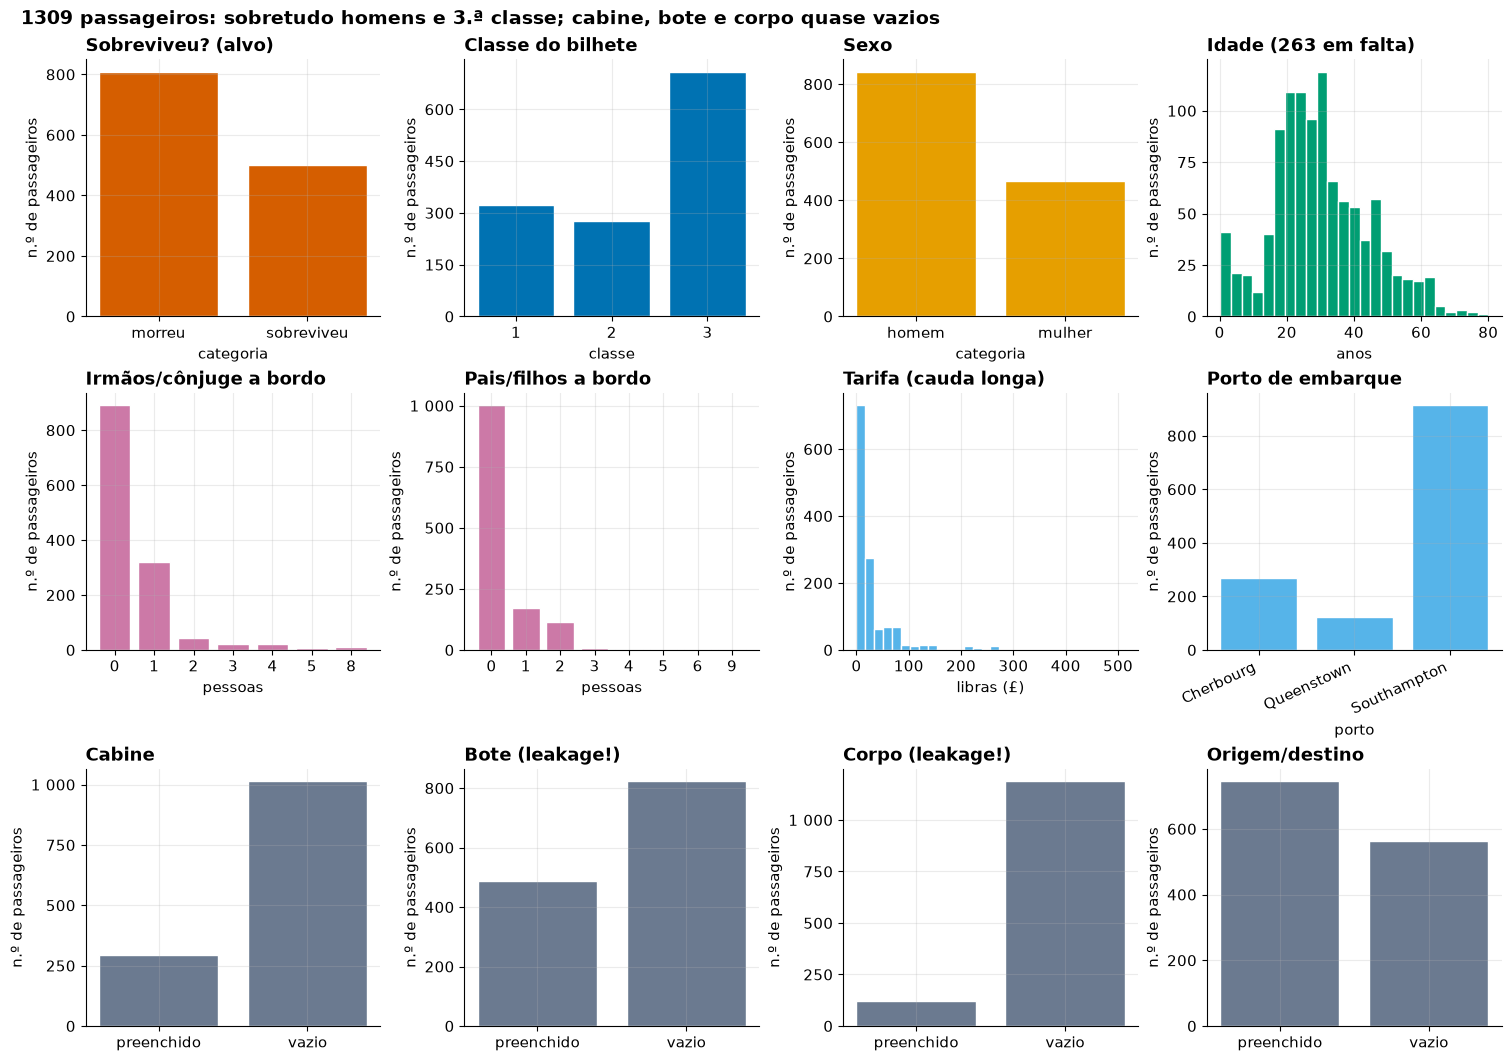

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10.5), layout="constrained")


def barras(ax, serie, titulo, cor, rot=None, xlabel="categoria"):
    vc = serie.value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color=PALETTE[cor], edgecolor="white")
    ax.set_title(titulo, fontsize=13)
    ax.set(xlabel=xlabel, ylabel="n.º de passageiros")
    ax.tick_params(labelsize=11)
    if rot:
        plt.setp(ax.get_xticklabels(), rotation=rot, ha="right")

barras(axes[0, 0], raw["survived"].map({0: "morreu", 1: "sobreviveu"}), "Sobreviveu? (alvo)", "red")
barras(axes[0, 1], raw["pclass"], "Classe do bilhete", "blue", xlabel="classe")
barras(axes[0, 2], raw["sex"].map({"female": "mulher", "male": "homem"}), "Sexo", "orange")
axes[0, 3].hist(raw["age"].dropna(), bins=25, color=PALETTE["green"], edgecolor="white")
axes[0, 3].set_title("Idade (263 em falta)", fontsize=13)
axes[0, 3].set(xlabel="anos", ylabel="n.º de passageiros")
barras(axes[1, 0], raw["sibsp"], "Irmãos/cônjuge a bordo", "purple", xlabel="pessoas")
barras(axes[1, 1], raw["parch"], "Pais/filhos a bordo", "purple", xlabel="pessoas")
axes[1, 2].hist(raw["fare"].dropna(), bins=30, color=PALETTE["sky"], edgecolor="white")
axes[1, 2].set_title("Tarifa (cauda longa)", fontsize=13)
axes[1, 2].set(xlabel="libras (£)", ylabel="n.º de passageiros")
barras(axes[1, 3], raw["embarked"].map({"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"}), "Porto de embarque", "sky", rot=25, xlabel="porto")
for ax, col, tit in [(axes[2, 0], "cabin", "Cabine"), (axes[2, 1], "boat", "Bote (leakage!)"), (axes[2, 2], "body", "Corpo (leakage!)"), (axes[2, 3], "home.dest", "Origem/destino")]:
    barras(ax, raw[col].notna().map({True: "preenchido", False: "vazio"}), tit, "grey", xlabel="")
for ax in (axes[0, 3], axes[1, 2]):
    ax.tick_params(labelsize=11)
    ax.xaxis.label.set_size(11)
    ax.yaxis.label.set_size(11)
for ax in axes.flat:
    pt_axis(ax, "y", 0, 5)
fig.suptitle("1309 passageiros: sobretudo homens e 3.ª classe; cabine, bote e corpo quase vazios", x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.show()

**Como ler:** há mais homens que mulheres e mais passageiros de 3.ª classe; quase todos viajavam sem irmãos/cônjuge nem pais/filhos; a tarifa tem cauda longa (poucos bilhetes caríssimos); `cabin`, `boat` e `body` estão sobretudo vazios. A sobrevivência por sexo e classe vem já a seguir (2.2).

### 2.1 Valores em falta

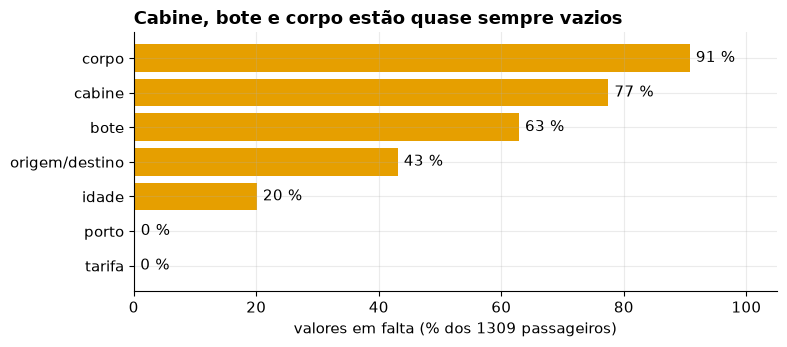

Em falta: age=263, cabin=1014, embarked=2, fare=1, boat=823, body=1188


In [5]:
na = raw.isna().mean().sort_values(ascending=False).mul(100)
na = na[na > 0]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(na.index[::-1], na.values[::-1], color=PALETTE["orange"])
for i, v in enumerate(na.values[::-1]):
    ax.text(v + 1, i, f"{fmt_pt(v, 0)} %", va="center")
ax.set(xlabel="valores em falta (% dos 1309 passageiros)", title="Cabine, bote e corpo estão quase sempre vazios")
ax.set_xlim(0, 105)
ax.set_yticks(range(len(na)), [{"cabin": "cabine", "boat": "bote", "body": "corpo", "age": "idade", "home.dest": "origem/destino", "embarked": "porto", "fare": "tarifa"}.get(c, c) for c in na.index[::-1]])
fig.tight_layout()
plt.show()
print("Em falta: " + ", ".join(f"{c}={int(raw[c].isna().sum())}" for c in ["age", "cabin", "embarked", "fare", "boat", "body"]))

Nem todos os "vazios" são iguais: `age` falta por **não ter sido registada** (263); `cabin` falta sobretudo para quem viajava em classes baixas (sem cabine registada); `boat` está vazio para quem **não** apanhou um bote, por isso o seu vazio **é informação** sobre o desfecho (leakage!). `embarked` (2) e `fare` (1) são casos pontuais.

### 2.2 Quem sobreviveu? Sexo, classe, idade, família, porto

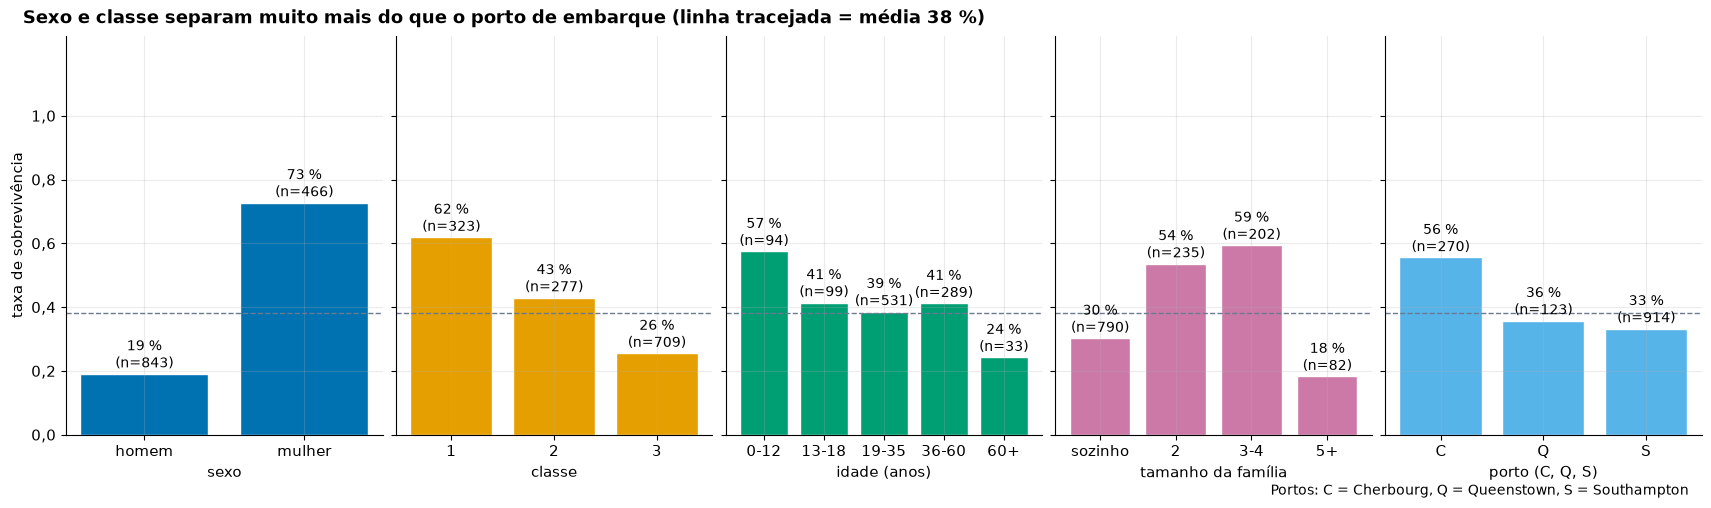

In [6]:
data = add_titanic_features(raw)          # cria title, family_size, is_alone, deck
data["age_group"] = pd.cut(data["age"], [0, 12, 18, 35, 60, 100], labels=["0-12", "13-18", "19-35", "36-60", "60+"])
data["fam_group"] = pd.cut(data["family_size"], [0, 1, 2, 4, 20], labels=["sozinho", "2", "3-4", "5+"])

data["sexo"] = data["sex"].map({"female": "mulher", "male": "homem"})
panels = [("sexo", "sexo"), ("pclass", "classe"), ("age_group", "idade (anos)"), ("fam_group", "tamanho da família"), ("embarked", "porto (C, Q, S)")]
fig, axes = plt.subplots(1, 5, figsize=(17, 4.8), sharey=True, layout="constrained")
for ax, (col, label), color in zip(axes, panels, ["blue", "orange", "green", "purple", "sky"]):
    g = data.groupby(col, observed=True)["survived"].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"], color=PALETTE[color], edgecolor="white")
    for x, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(x, m + 0.02, f"{fmt_pt(100 * (m), 0)} %\n(n={n})", ha="center", fontsize=10)
    ax.axhline(data["survived"].mean(), color=PALETTE["grey"], ls="--", lw=1)
    ax.set(xlabel=label, ylim=(0, 1.25), ylabel="taxa de sobrevivência" if col == "sexo" else "")
    ax.tick_params(labelsize=11)
    pt_axis(ax, "y", 1, 6)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
fig.suptitle("Sexo e classe separam muito mais do que o porto de embarque (linha tracejada = média 38 %)", x=0.01, ha="left", fontweight="bold")
fig.text(0.99, -0.02, "Portos: C = Cherbourg, Q = Queenstown, S = Southampton", ha="right", fontsize=10)
plt.show()

### 2.3 Interação classe × sexo
Os efeitos **não se somam**: o que a classe faz depende do sexo. Um heatmap mostra-o melhor que dois gráficos separados.

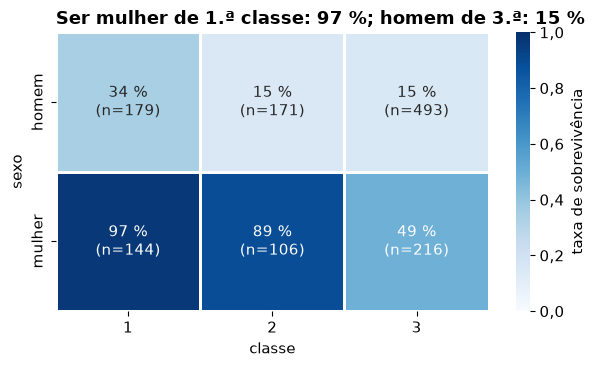

In [7]:
tab = data.pivot_table(index="sexo", columns="pclass", values="survived", aggfunc="mean")
counts = data.pivot_table(index="sexo", columns="pclass", values="survived", aggfunc="size")
fig, ax = plt.subplots(figsize=(6.2, 3.8))
sns.heatmap(tab, annot=[[f"{fmt_pt(100 * (tab.iloc[i, j]), 0)} %\n(n={counts.iloc[i, j]})" for j in range(3)] for i in range(2)], fmt="",
            cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "taxa de sobrevivência"}, linewidths=1, ax=ax)
ax.set_xlabel("classe"); ax.set_ylabel("sexo"); ax.grid(False)
pt_axis(ax.collections[0].colorbar.ax, "y", 1, 6)
ax.set_title("Ser mulher de 1.ª classe: 97 %; homem de 3.ª: 15 %")
fig.tight_layout()
plt.show()

### 2.4 Títulos a partir do nome

In [8]:
t = data.groupby("title")["survived"].agg(n="size", taxa="mean").sort_values("n", ascending=False)
t["taxa"] = (t["taxa"] * 100).round(0)
display(t.T)
print("Idade mediana por título:", data.groupby("title")["age"].median().round(1).to_dict())

title,Mr,Miss,Mrs,Master,Rare
n,757.0,264.0,198.0,61.0,29.0
taxa,16.0,68.0,79.0,51.0,38.0


Idade mediana por título: {'Master': 4.0, 'Miss': 22.0, 'Mr': 29.0, 'Mrs': 35.0, 'Rare': 47.5}


O nome tem informação: **Master** = rapaz novo, **Miss** = mulher solteira/jovem, **Mrs** = casada, **Mr** = homem adulto. O título dá-nos uma pista sobre a idade para **imputar** valores em falta de forma mais inteligente que a mediana global.

### 💬 Discussão — O que revelam os dados sobre "mulheres e crianças primeiro"?
Vê os gráficos por sexo, idade e o heatmap. A regra aplicou-se igualmente a todos? Que fatores além do sexo e da idade mudam a probabilidade?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Sexo é o fator mais forte (mulheres ≈ 73 % vs. homens ≈ 19 %), e os rapazes novos (**Master**) também se salvam mais que os homens adultos. Mas a regra **não foi igual para todos**: no heatmap, mulheres de 1.ª classe sobreviveram **97 %**, de 2.ª **89 %**, de 3.ª só **49 %**; homens de 1.ª **34 %**, de 2.ª e 3.ª **15 %**. Ou seja, a **classe** (acesso físico aos convés dos botes, localização das cabines, ordem em que foram avisados) modula o efeito do sexo. O porto de embarque quase não importa por si só: reflete a composição de classes de cada porto (confusão!). Cuidado: estes dados descrevem **o que aconteceu**, não "o que devia" ter acontecido.
</details>

<a id="sec-3"></a>
# 3. 🧹 Data Preparation (preparação dos dados)

Passos, com a preocupação constante de **não deixar a informação do teste passar para o treino**:

1. **Variáveis novas** que só usam informação de cada linha (`add_titanic_features`): `title` (do nome), `family_size = sibsp + parch + 1`, `is_alone`, `deck` (1.ª letra da cabine; `U` = desconhecido). Podem ser calculadas **antes** do *split* porque não aprendem nada com o conjunto.
2. **Divisão estratificada** (80/20, mantendo a proporção de sobreviventes em cada parte).
3. **Imputação da idade** pela **mediana por título**, **dentro do *pipeline*** (`GroupMedianImputer`): as medianas aprendem-se só no treino.
4. **Codificação**: números estandardizados; categorias em *one-hot*.
5. Excluídas: `boat`, `body` (leakage), `ticket`, `home.dest` (identificadores/texto livre).

In [9]:
X = data[TITANIC_FEATURES]
y = data["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Treino: {len(X_train)} · Teste: {len(X_test)} · sobreviventes: treino {fmt_pt(100 * (y_train.mean()), 1)} %, teste {fmt_pt(100 * (y_test.mean()), 1)} %")
print("Características usadas:", TITANIC_FEATURES)

Treino: 1047 · Teste: 262 · sobreviventes: treino 38,2 %, teste 38,2 %
Características usadas: ['age', 'fare', 'sibsp', 'parch', 'family_size', 'pclass', 'sex', 'embarked', 'title', 'deck', 'is_alone']


In [10]:
prep = make_titanic_preprocessor().fit(X_train, y_train)
print("Medianas de idade aprendidas SÓ no treino:", {k: round(v, 1) for k, v in prep.named_steps["age_by_title"].medians_.items()})
Z = prep.transform(X_test)
print(f"Teste transformado: {Z.shape[0]} linhas × {Z.shape[1]} colunas, NAs restantes: {int(np.isnan(Z).sum())}")

Medianas de idade aprendidas SÓ no treino: {'Master': 4.0, 'Miss': 21.5, 'Mr': 29.0, 'Mrs': 35.5, 'Rare': 46.0}
Teste transformado: 262 linhas × 28 colunas, NAs restantes: 0


### 💬 Discussão — Porque imputar dentro do pipeline?
Calcular a mediana da idade com **todos** os 1309 passageiros antes do *split* é mais simples. Porque é que não é boa ideia, mesmo que a diferença numérica seja pequena?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Porque o teste deixa de ser "dados que o modelo nunca viu": a mediana usada no treino já contém informação das linhas do teste. A fuga aqui é **pequena** (uma mediana por título), mas o hábito é perigoso: com imputação por vizinhos, *target encoding* ou seleção de variáveis, a fuga pode inflacionar as métricas. Dentro do *pipeline*, a validação cruzada reaprende as medianas **em cada *fold*** e o teste fica realmente intocado. Regra prática: *tudo o que tem `fit` vive no pipeline*.
</details>

<a id="sec-4"></a>
# 4. 🚨 Leakage: quando a accuracy mente

***Data leakage*** (fuga de informação) é usar, para treinar, informação que **não estará disponível no momento da previsão**, ou que **é consequência do alvo**. As métricas ficam espetaculares e o modelo, inútil.

No Titanic, `boat` (bote em que a pessoa embarcou) e `body` (n.º do corpo recuperado) só existem **depois** do naufrágio. Quem tem um `boat` quase de certeza sobreviveu; quem tem um `body` morreu. Vamos ver o que acontece se os usarmos:

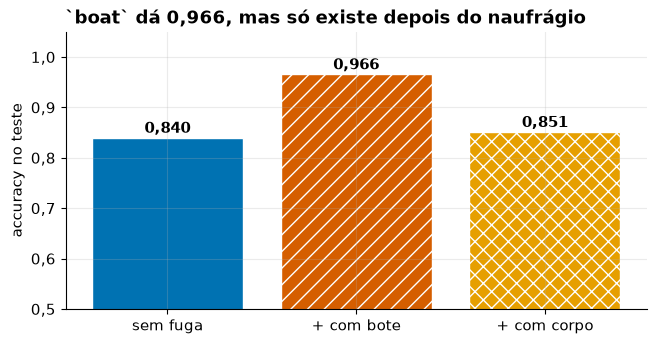

{'sem fuga': 0.84, '+ com bote': 0.966, '+ com corpo': 0.851}

Percentagem de sobreviventes entre quem tem bote: 98,1 % · entre quem tem corpo registado: 0,0 %


In [11]:
def make_leaky_preprocessor(extra):
    """Igual a make_titanic_preprocessor, mas com colunas extra (sim/não) tratadas como categorias."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", dtype=float))])
    cols = ColumnTransformer([("num", numeric, TITANIC_NUMERIC), ("cat", categorical, TITANIC_CATEGORICAL + extra)], verbose_feature_names_out=False)
    return Pipeline([("age_by_title", GroupMedianImputer("age", "title")), ("columns", cols)])


leak = data.copy()
leak["has_boat"] = leak["boat"].notna().map({True: "yes", False: "no"})
leak["has_body"] = leak["body"].notna().map({True: "yes", False: "no"})
resultados = {}
for nome, extra in {"sem fuga": [], "+ com bote": ["has_boat"], "+ com corpo": ["has_body"]}.items():
    cols = TITANIC_FEATURES + extra
    Xtr, Xte, ytr, yte = train_test_split(leak[cols], leak["survived"], test_size=0.2, stratify=leak["survived"], random_state=42)
    clf = Pipeline([("prep", make_leaky_preprocessor(extra)), ("lr", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr)
    resultados[nome] = accuracy_score(yte, clf.predict(Xte))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
cores = [PALETTE["blue"], PALETTE["red"], PALETTE["orange"]]
ax.bar(list(resultados), list(resultados.values()), color=cores, hatch=["", "//", "xx"], edgecolor="white")
for i, v in enumerate(resultados.values()):
    ax.text(i, v + 0.01, f"{fmt_pt(v, 3)}", ha="center", fontweight="bold")
pt_axis(ax, "y", 1, 6)
ax.set(ylabel="accuracy no teste", ylim=(0.5, 1.05), title="`boat` dá 0,966, mas só existe depois do naufrágio")
plt.show()
print({k: round(v, 3) for k, v in resultados.items()})
print("\nPercentagem de sobreviventes entre quem tem bote:", f"{fmt_pt(100 * (leak.loc[leak['boat'].notna(), 'survived'].mean()), 1)} %",
      "· entre quem tem corpo registado:", f"{fmt_pt(100 * (leak.loc[leak['body'].notna(), 'survived'].mean()), 1)} %")

> ⚠️ **Cuidado:** a accuracy sobe de **0,840** para **0,966** com `has_boat`. Parece ótimo, mas é **inútil**: em produção (antes do naufrágio, ou durante a evacuação), não sabemos em que bote a pessoa vai ficar, *porque isso é precisamente o resultado que queremos prever*. O modelo "aprendeu" o desfecho, não o risco. O mesmo para `body`: só existe para quem **morreu** e foi recuperado (0 % de sobreviventes entre quem tem corpo registado). A accuracy sobe menos (0,851) porque o modelo já acertava bastante nos que morrem, mas a variável é igualmente ilegítima.

**Como detetar *leakage*:** (1) resultados bons demais; (2) uma variável com importância desproporcionada; (3) perguntar para cada coluna: *"estará disponível, com este valor, no momento em que precisamos de prever?"*; (4) olhar para a cronologia dos dados.

### 💬 Discussão — Há *leakage* na tua área?
Dá um exemplo (fora do Titanic) de uma variável que parece preditiva mas só é conhecida depois do desfecho. Como a descobririas?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Exemplos: prever **cancelamento de subscrição** usando "data do pedido de cancelamento"; prever **fraude** usando "estado da investigação"; prever **diagnóstico** usando "medicação prescrita para essa doença"; prever **atraso do voo** com a hora real de descolagem. Aqui o sinal é a diferença **0,966 vs. 0,840**: um salto de 12 pontos só por acrescentar *uma* coluna binária é suspeito. Estratégias: lista de variáveis com **momento de disponibilidade**, validação **temporal** (treinar no passado, testar no futuro), e rever com quem conhece o processo de recolha de dados.
</details>

<a id="sec-5"></a>
# 5. 🤖 Modeling (modelação)

Três candidatos e um *baseline*, todos avaliados com **StratifiedKFold de 5** no treino (cada *fold* mantém a proporção de sobreviventes):

| Modelo | Nota |
|---|---|
| **Baseline** (classe maioritária) | prevê sempre "morre"; é a fasquia mínima |
| **Regressão logística** | linear nas características; dá **probabilidades** bem comportadas e é fácil de explicar |
| **Random forest** | 300 árvores; apanha interações |
| **HistGradientBoosting** | árvores em sequência, cada uma corrige as anteriores |

## 🧠 Como funciona: cada modelo, em dados reais
Antes de comparar, vamos **ver** cada modelo a trabalhar nos passageiros.

### 🧠 Baseline: "prever sempre a classe mais comum"
Diz sempre "morre" (62 % dos passageiros morreram), por isso acerta em ≈ 62 % **sem aprender nada**. É a régua mínima.

### 🧠 Regressão logística: "uma soma ponderada transformada em probabilidade"
**Ideia:** calcula uma pontuação `z = b0 + b1·x1 + …` e passa-a por uma curva em "S" (a **sigmoide**), que a transforma numa probabilidade entre 0 e 1. **Analogia:** um termómetro que converte "sinais a favor menos sinais contra" numa percentagem. **Como aprende:** escolhe os pesos que tornam mais prováveis as respostas observadas. **Bom para:** probabilidades claras e coeficientes interpretáveis. **Cuidado:** a fronteira é linear. Abaixo, com **uma só** característica (a tarifa, em escala logarítmica) para ver a curva.

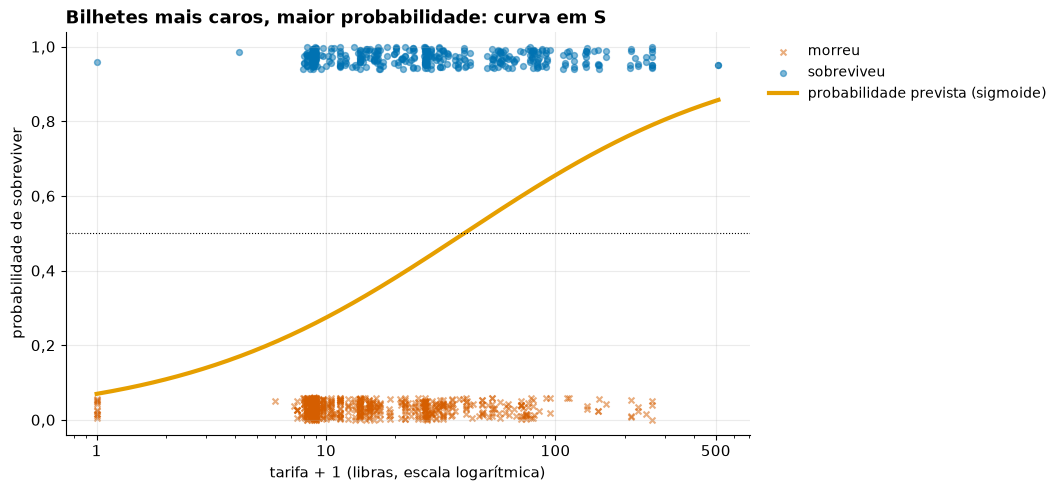

Com tarifa de 8 £ → 26%; com 100 £ → 66%  (só com esta característica).


In [12]:
tr = X_train.assign(y=y_train).dropna(subset=["fare"])
x_plot = tr["fare"] + 1
lr1 = LogisticRegression().fit(np.log(x_plot).to_frame("log_tarifa"), tr["y"])
grelha = np.logspace(0, np.log10(x_plot.max()), 200)
prob = lr1.predict_proba(pd.DataFrame({"log_tarifa": np.log(grelha)}))[:, 1]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(10.5, 4.8), layout="constrained")
for valor, marcador, cor, nome in [(0, "x", "red", "morreu"), (1, "o", "blue", "sobreviveu")]:
    m = tr["y"] == valor
    ax.scatter(x_plot[m], (0.0 if valor == 0 else 0.94) + rng.uniform(0, 0.06, m.sum()), marker=marcador, s=18, alpha=.5, color=PALETTE[cor], label=nome)
ax.plot(grelha, prob, color=PALETTE["orange"], lw=3, label="probabilidade prevista (sigmoide)")
ax.axhline(0.5, color="black", lw=.8, ls=":")
ax.set_xscale("log")
ax.set_xticks([1, 10, 100, 500], ["1", "10", "100", "500"])
ax.set(xlabel="tarifa + 1 (libras, escala logarítmica)", ylabel="probabilidade de sobreviver", title="Bilhetes mais caros, maior probabilidade: curva em S")
ax.legend(fontsize=10, loc="upper left", bbox_to_anchor=(1.01, 1))
pt_axis(ax, "y", 1, 6)
ax.set_ylim(-0.04, 1.04)
plt.show()
print(f"Com tarifa de 8 £ → {lr1.predict_proba(pd.DataFrame({'log_tarifa': [np.log(9)]}))[0, 1]:.0%}; com 100 £ → {lr1.predict_proba(pd.DataFrame({'log_tarifa': [np.log(101)]}))[0, 1]:.0%}  (só com esta característica).")

### 🧠 Árvore de decisão (profundidade 3): "um fluxograma de perguntas"
**Ideia:** faz perguntas sim/não sobre as características, da mais informativa para a menos, até chegar a uma "folha" que prevê a classe mais comum nessa folha. **Analogia:** o jogo das 20 perguntas. **Bom para:** ser legível por qualquer pessoa. **Cuidado:** árvores profundas decoram o treino. Aqui usamos 4 características simples: `é mulher`, `classe`, `idade` (imputada pela mediana do título) e `tamanho da família`.

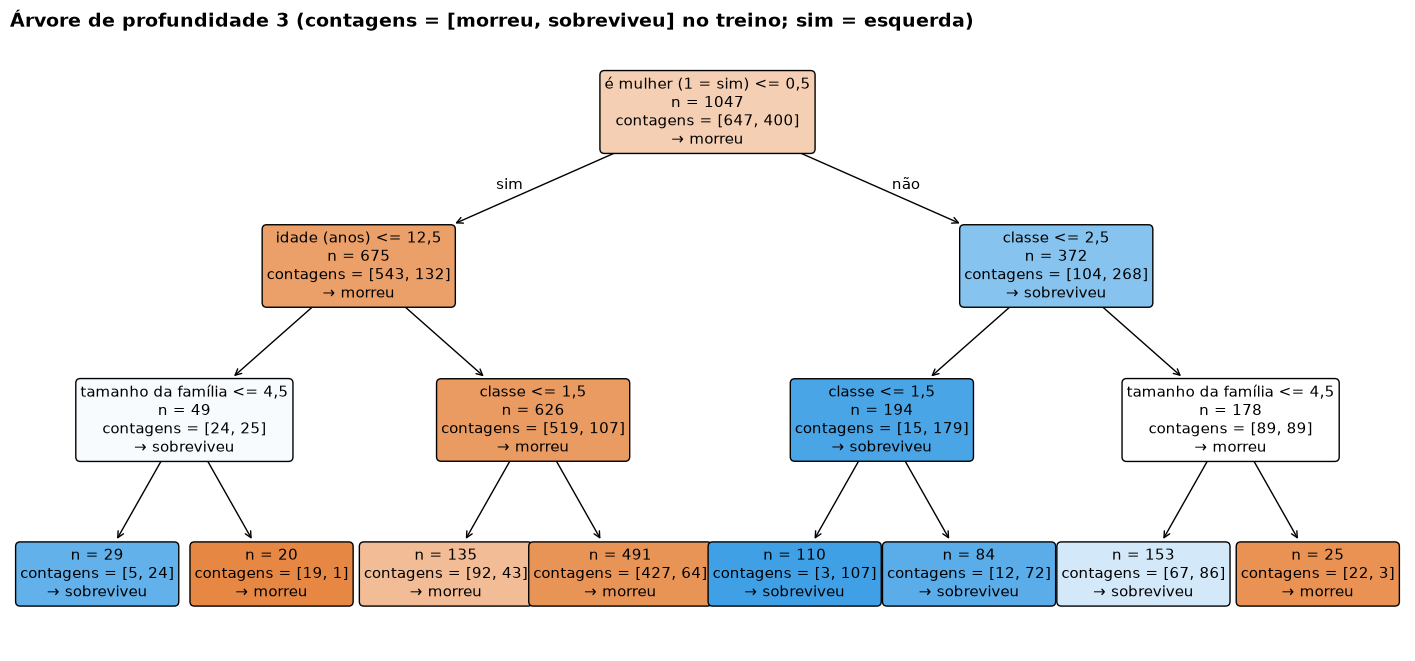

Accuracy: treino 0,811 · teste 0,836


In [13]:
import re

from sklearn.tree import DecisionTreeClassifier, plot_tree

gm = GroupMedianImputer("age", "title").fit(X_train)


def simples(d):
    d = gm.transform(d)
    return pd.DataFrame({"é mulher (1 = sim)": (d["sex"] == "female").astype(int), "classe": d["pclass"].astype(int),
                         "idade (anos)": d["age"], "tamanho da família": d["family_size"]})


S_train, S_test = simples(X_train), simples(X_test)
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(S_train, y_train)
fig, ax = plt.subplots(figsize=(18, 8))
notas = plot_tree(tree3, feature_names=list(S_train.columns), class_names=["morreu", "sobreviveu"], filled=True, rounded=True, impurity=False, fontsize=11, precision=1, ax=ax)
for t in notas:   # traduz e arredonda as contagens
    txt = t.get_text().replace("samples = ", "n = ").replace("value = ", "contagens = ").replace("True", "sim").replace("False", "não").replace("class = ", "→ ")
    t.set_text(re.sub(r"(\d+)\.0\b", r"\1", txt).replace(".", ","))
ax.set_title("Árvore de profundidade 3 (contagens = [morreu, sobreviveu] no treino; sim = esquerda)", fontsize=14)
plt.show()
print(f"Accuracy: treino {fmt_pt(tree3.score(S_train, y_train), 3)} · teste {fmt_pt(tree3.score(S_test, y_test), 3)}")

**Como ler** (cada caixa mostra a pergunta, `n` = nº de passageiros, `contagens` = [morreu, sobreviveu] no treino e a classe prevista; **sim** = condição verdadeira, ramo da esquerda):
- **Homem, idade ≤ 12,5**, família ≤ 4,5 → [5, 24]: **sobrevive** (rapazes de famílias pequenas); com família > 4,5 → [19, 1]: morre.
- **Homem, idade > 12,5**, 1.ª classe → [92, 43]: **morre**; 2.ª/3.ª classe → [427, 64]: **morre**.
- **Mulher, 1.ª classe** → [3, 107] e **2.ª classe** → [12, 72]: **sobrevive**.
- **Mulher, 3.ª classe**, família ≤ 4,5 → [67, 86]: sobrevive (por pouco); família > 4,5 → [22, 3]: morre.

Com apenas 3 perguntas, a árvore resume "mulheres e crianças primeiro" e o papel da classe.

### 🧠 Random forest: "votação de muitas árvores"
**Ideia:** treina centenas de árvores, cada uma com uma amostra diferente dos passageiros e das características, e **faz a média das probabilidades** (ou conta os votos). **Analogia:** um júri de 300 pessoas: nenhum é perfeito, mas a decisão coletiva é mais estável. Abaixo, o que **cada uma das 300 árvores** diz sobre dois passageiros do teste.

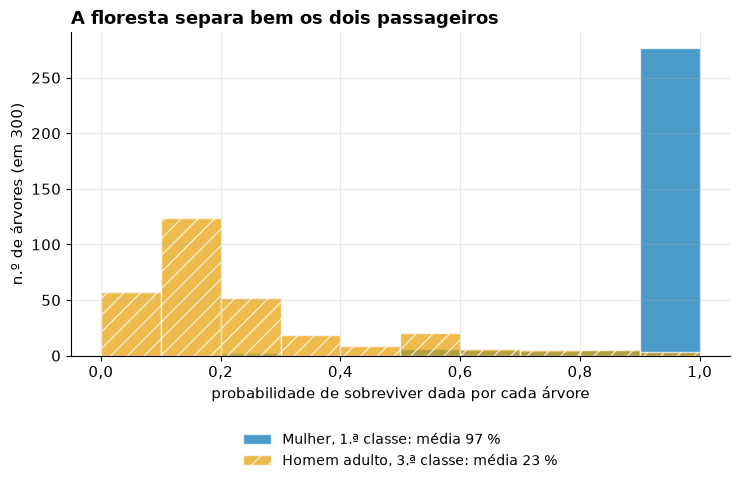

Probabilidade da floresta (média das árvores): {'Mulher, 1.ª classe': '97 %', 'Homem adulto, 3.ª classe': '23 %'}


In [14]:
rf_demo = Pipeline([("prep", make_titanic_preprocessor()),
                    ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1))]).fit(X_train, y_train)
casos = pd.concat([X_test[(X_test["sex"] == "female") & (X_test["pclass"] == "1")].head(1), X_test[(X_test["sex"] == "male") & (X_test["pclass"] == "3") & (X_test["title"] == "Mr")].head(1)])
nomes_casos = ["Mulher, 1.ª classe", "Homem adulto, 3.ª classe"]
Zc = rf_demo[:-1].transform(casos)
votos = np.array([t.predict_proba(Zc)[:, 1] for t in rf_demo[-1].estimators_])     # 300 árvores × 2 passageiros
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for k, (nome, cor, hatch) in enumerate(zip(nomes_casos, ["blue", "orange"], ["", "//"])):
    ax.hist(votos[:, k], bins=np.linspace(0, 1, 11), alpha=.7, color=PALETTE[cor], hatch=hatch, edgecolor="white", label=f"{nome}: média {fmt_pt(100 * (votos[:, k].mean()), 0)} %")
ax.set(xlabel="probabilidade de sobreviver dada por cada árvore", ylabel="n.º de árvores (em 300)", title="A floresta separa bem os dois passageiros")
pt_axis(ax, "x", 1, 6)
ax.legend(fontsize=10, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)
plt.show()
print("Probabilidade da floresta (média das árvores):", {n: f"{fmt_pt(100 * (votos[:, k].mean()), 0)} %" for k, n in enumerate(nomes_casos)})

### 🧠 *Gradient boosting* (`HistGradientBoosting`): "árvores pequenas em sequência, cada uma corrige a anterior"
**Ideia:** a 1.ª árvore faz uma previsão grosseira; a 2.ª aprende **o erro que sobrou**; a 3.ª corrige o que ainda falta… e somam-se. **Analogia:** rever um texto várias vezes, corrigindo a cada passagem. **Cuidado:** com muitas árvores pode decorar o treino. O gráfico mostra a accuracy de validação (5-fold) à medida que juntamos árvores:

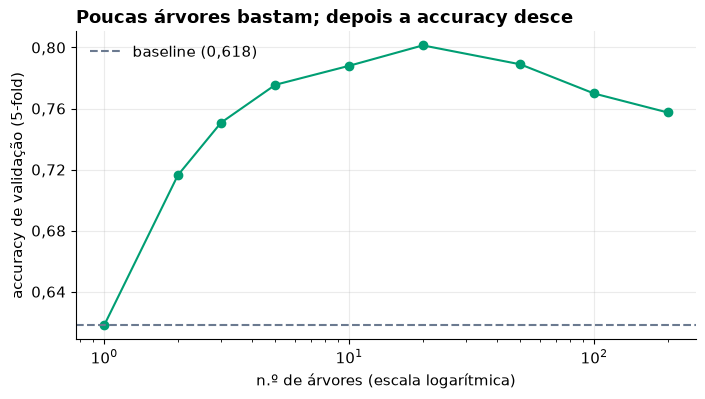

{1: 0.618, 2: 0.716, 3: 0.751, 5: 0.776, 10: 0.788, 20: 0.801, 50: 0.789, 100: 0.77, 200: 0.757}


In [15]:
cv_demo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
passos = [1, 2, 3, 5, 10, 20, 50, 100, 200]
acc = []
for n in passos:
    m = Pipeline([("prep", make_titanic_preprocessor()), ("hgb", HistGradientBoostingClassifier(max_iter=n, early_stopping=False, random_state=42))])
    acc.append(float(cross_validate(m, X_train, y_train, cv=cv_demo, scoring="accuracy")["test_score"].mean()))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(passos, acc, marker="o", color=PALETTE["green"])
ax.axhline(0.618, color=PALETTE["grey"], ls="--", label="baseline (0,618)")
ax.set_xscale("log")
ax.set(xlabel="n.º de árvores (escala logarítmica)", ylabel="accuracy de validação (5-fold)", title="Poucas árvores bastam; depois a accuracy desce")
pt_axis(ax, "y", 2, 6)
ax.legend()
plt.show()
print({n: round(a, 3) for n, a in zip(passos, acc)})

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def make_model(clf):
    return Pipeline([("prep", make_titanic_preprocessor()), ("clf", clf)])


models = {
    "Baseline (maioritária)": make_model(DummyClassifier(strategy="most_frequent")),
    "Regressão logística": make_model(LogisticRegression(max_iter=1000)),
    "Random forest": make_model(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)),
    "HistGradientBoosting": make_model(HistGradientBoostingClassifier(random_state=42)),
}
rows = {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"])
    rows[name] = {"CV accuracy": r["test_accuracy"].mean(), "± desvio": r["test_accuracy"].std(), "CV ROC-AUC": r["test_roc_auc"].mean()}
cv_table = pd.DataFrame(rows).T
cv_table.round(3)

,CV accuracy,± desvio,CV ROC-AUC
Baseline (maioritária),0.618,0.001,0.500
Regressão logística,0.803,0.012,0.848
Random forest,0.805,0.011,0.853
HistGradientBoosting,0.770,0.022,0.830


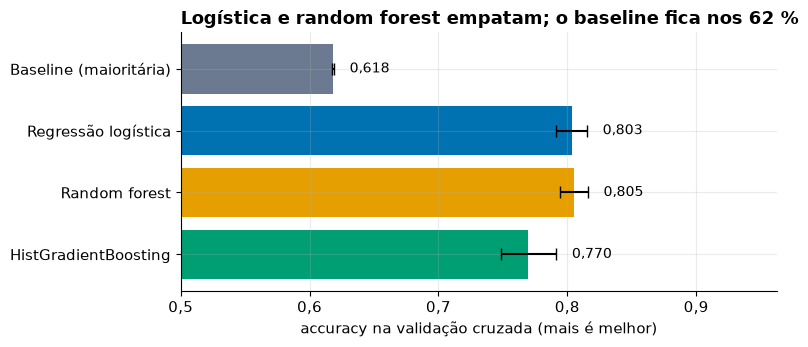

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [PALETTE["grey"], PALETTE["blue"], PALETTE["orange"], PALETTE["green"]]
ax.barh(cv_table.index[::-1], cv_table["CV accuracy"][::-1], xerr=cv_table["± desvio"][::-1], color=cores[::-1], capsize=4)
label_bars(ax, cv_table["CV accuracy"][::-1].values, cv_table["± desvio"][::-1].values, decimals=3)
pt_axis(ax, "x", 1, 6)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9])
ax.set(xlabel="accuracy na validação cruzada (mais é melhor)", xlim=(0.5, None), title="Logística e random forest empatam; o baseline fica nos 62 %")
fig.tight_layout()
plt.show()

### 💬 Discussão — O modelo mais simples chega?
A regressão logística e a *random forest* ficam praticamente empatadas, e o *gradient boosting* até pior. O que escolherias para pôr em produção, e porquê?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Na validação cruzada: logística **0,803 ± 0,012**, random forest **0,805 ± 0,011**, HistGradientBoosting **0,770 ± 0,022** (baseline 0,618). A diferença entre as duas primeiras é muito inferior ao desvio entre *folds*: **empate técnico**. Com ~1000 linhas e poucas variáveis, os modelos mais flexíveis não têm vantagem real, e o boosting até sofre com a variância. Escolheríamos a **regressão logística**: mais simples, probabilidades bem calibradas, explicável (cada coeficiente tem sentido), mais fácil de monitorizar. Só trocaríamos se a validação o justificasse com folga.
</details>

### ✏️ Exercício 1 — O que acontece sem o título?
**Dificuldade:** ⭐⭐

Faz uma **ablação**: retira `title` das características e repete a validação cruzada da regressão logística. O `title` ajuda (também alimenta a imputação da idade)? Completa o `TODO`.

In [18]:
# o GroupMedianImputer precisa do título, por isso aqui imputamos a idade pela mediana global
cat_sem_titulo = [c for c in TITANIC_CATEGORICAL if c != "title"]
pre_sem = ColumnTransformer([
    ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), TITANIC_NUMERIC),
    ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), cat_sem_titulo),
])
modelo_sem = make_pipeline(pre_sem, LogisticRegression(max_iter=1000))
# TODO: calcula a accuracy média em validação cruzada (cv) com X_train[TITANIC_NUMERIC + cat_sem_titulo]
print("accuracy COM título (referência):", cv_table.loc["Regressão logística", "CV accuracy"].round(3))

accuracy COM título (referência): 0.803


<details>
<summary>💡 Ver solução</summary>

```python
cat_sem_titulo = [c for c in TITANIC_CATEGORICAL if c != "title"]
pre_sem = ColumnTransformer([
    ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), TITANIC_NUMERIC),
    ("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")), ("o", OneHotEncoder(handle_unknown="ignore"))]), cat_sem_titulo),
])
modelo_sem = make_pipeline(pre_sem, LogisticRegression(max_iter=1000))
r = cross_validate(modelo_sem, X_train[TITANIC_NUMERIC + cat_sem_titulo], y_train, cv=cv, scoring="accuracy")
print(f"SEM título: {fmt_pt(r['test_score'].mean(), 3)} ± {fmt_pt(r['test_score'].std(), 3)} · COM título: {fmt_pt(cv_table.loc['Regressão logística', 'CV accuracy'], 3)}")
```

Sem o título a accuracy desce cerca de 2 pontos (0,784 vs. 0,803, uns 1,5 desvios entre *folds*): ajuda, mas pouco, porque o `title` é em parte redundante com `sex` e `age`. A ablação diz-nos o **valor marginal** de uma variável. Atenção: aqui a idade passa a ser imputada pela mediana global, por isso o efeito mistura as duas coisas.
</details>

<a id="sec-6"></a>
# 6. 📏 Evaluation (avaliação)

Ajustamos ao treino completo e medimos no **teste**. Para classificação, a **matriz de confusão** é o ponto de partida:

|  | previsto: morre | previsto: sobrevive |
|---|---|---|
| **real: morre** | TN (verdadeiro negativo) | **FP** (falso positivo) |
| **real: sobrevive** | **FN** (falso negativo) | TP (verdadeiro positivo) |

- **Accuracy** = (TP+TN)/total: fração certa. Engana com classes desequilibradas.
- ***Precision*** = TP/(TP+FP): "quando digo *sobrevive*, quantas vezes acerto?"
- ***Recall*** = TP/(TP+FN): "dos que sobrevivem, quantos apanho?"
- **F1**: média harmónica de *precision* e *recall*.
- **ROC-AUC** e **PR-AUC** (*average precision*): qualidade das **probabilidades** em todos os limiares (ROC: TPR vs FPR; PR: precision vs recall).

In [19]:
fitted = {n: m.fit(X_train, y_train) for n, m in models.items()}
probs = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
rows = {}
for n, p in probs.items():
    pred = (p >= 0.5).astype(int)
    rows[n] = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
               "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
               "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)}
test_table = pd.DataFrame(rows).T
test_table.round(3)

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Baseline (maioritária),0.618,0.000,0.00,0.000,0.500,0.382
Regressão logística,0.840,0.796,0.78,0.788,0.885,0.856
Random forest,0.851,0.821,0.78,0.800,0.900,0.877
HistGradientBoosting,0.824,0.793,0.73,0.760,0.886,0.831


### 6.0 Comparar os modelos: as métricas em barras

Com TP, FP, FN, TN da matriz de confusão (limiar 0,5):

$$	ext{accuracy}=rac{TP+TN}{TP+TN+FP+FN}\quad 	ext{precision}=rac{TP}{TP+FP}\quad 	ext{recall}=rac{TP}{TP+FN}\quad F_1=rac{2\cdot	ext{precision}\cdot	ext{recall}}{	ext{precision}+	ext{recall}}$$

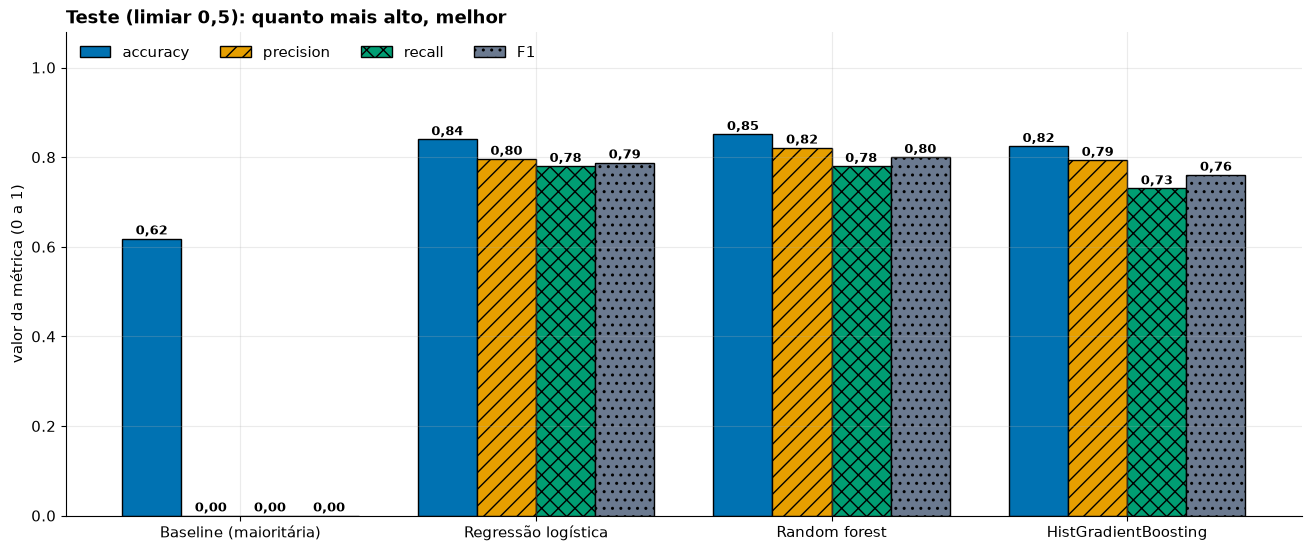

In [20]:
metricas = ["accuracy", "precision", "recall", "F1"]
nomes = list(test_table.index)
x = np.arange(len(nomes)); larg = 0.2
cores = [PALETTE["blue"], PALETTE["orange"], PALETTE["green"], PALETTE["grey"]]
hatches = ["", "//", "xx", ".."]
fig, ax = plt.subplots(figsize=(13, 5.4), layout="constrained")
for j, m in enumerate(metricas):
    vals = test_table[m].values
    barras = ax.bar(x + (j - 1.5) * larg, vals, larg, color=cores[j], hatch=hatches[j], edgecolor="black", label=m)
    for b_, v_ in zip(barras, vals):
        ax.annotate(fmt_pt(v_, 2), (b_.get_x() + b_.get_width() / 2, v_), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(x, nomes); ax.set_ylim(0, 1.08); ax.set_ylabel("valor da métrica (0 a 1)")
ax.set_title("Teste (limiar 0,5): quanto mais alto, melhor", loc="left", fontweight="bold")
ax.legend(ncols=4, frameon=False, loc="upper left")
plt.show()

### ✏️ A tua decisão: qual é o melhor modelo?

Escolhe um modelo e **justifica** com as métricas do gráfico, com a **ROC-AUC/PR-AUC** da tabela e com um critério que não seja uma métrica (simplicidade, explicabilidade). Lembra-te: a *accuracy* sozinha engana (o *baseline* já tem 62 %), e `precision` e `recall` trocam-se pelo limiar.

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

A regressão logística, a floresta aleatória e o *gradient boosting* ficam muito próximos (accuracy 0,82 a 0,85; ROC-AUC 0,885 a 0,900), todos muito acima do *baseline* (0,618). Como a logística é a mais simples e explicável, e a diferença para a floresta é pequena com apenas 262 passageiros de teste, é uma escolha razoável; a floresta tem a melhor accuracy e AUC por pouco. Discutir: que custo tem errar para cada lado? (secção 6.2).
</details>

In [21]:
escolha = "Regressão logística"   # ← muda para o modelo que escolheres
ranking = test_table.sort_values("F1", ascending=False)
print("Ranking pelo F1 (maior é melhor):")
display(ranking.round(3))
print(f"A tua escolha: {escolha}  →  posição {list(ranking.index).index(escolha) + 1} de {len(ranking)} no F1")

Ranking pelo F1 (maior é melhor):


,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Random forest,0.851,0.821,0.78,0.800,0.900,0.877
Regressão logística,0.840,0.796,0.78,0.788,0.885,0.856
HistGradientBoosting,0.824,0.793,0.73,0.760,0.886,0.831
Baseline (maioritária),0.618,0.000,0.00,0.000,0.500,0.382


A tua escolha: Regressão logística  →  posição 2 de 4 no F1


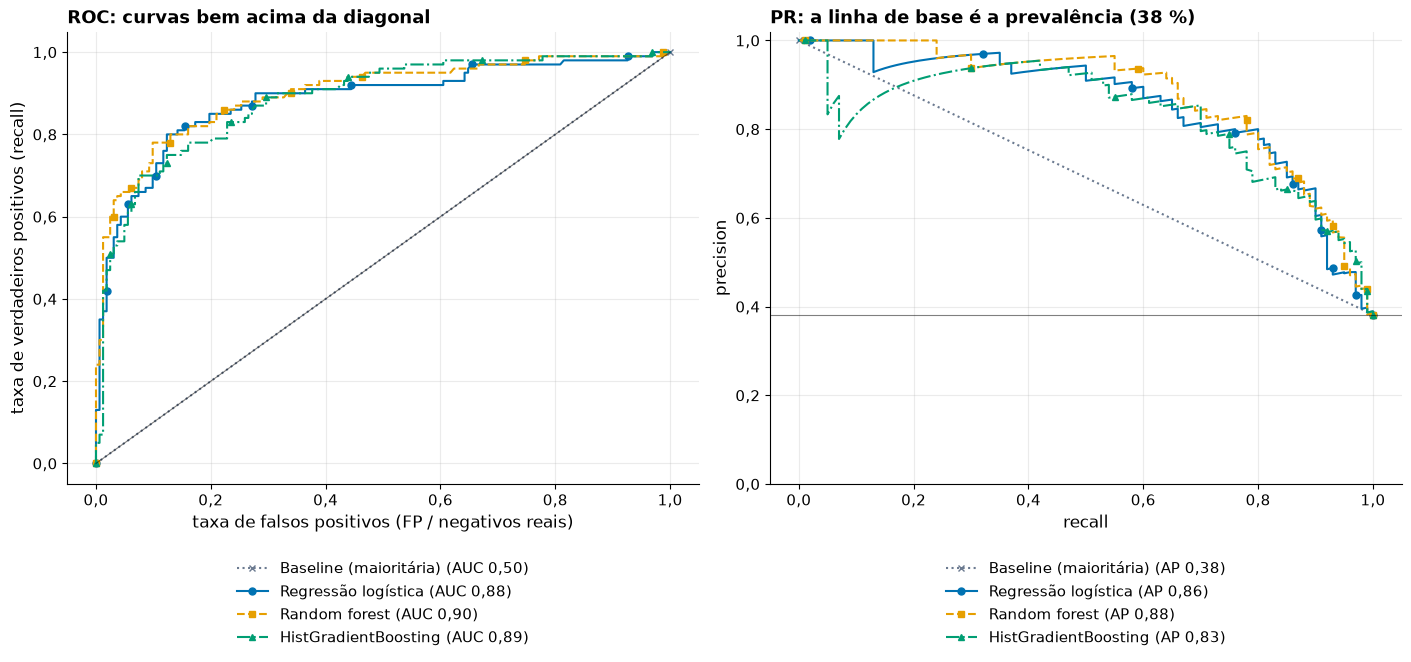

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), layout="constrained")
estilos = [("Baseline (maioritária)", PALETTE["grey"], ":", "x"), ("Regressão logística", PALETTE["blue"], "-", "o"),
           ("Random forest", PALETTE["orange"], "--", "s"), ("HistGradientBoosting", PALETTE["green"], "-.", "^")]
for n, c, ls, mk in estilos:
    fpr, tpr, _ = roc_curve(y_test, probs[n])
    axes[0].plot(fpr, tpr, color=c, ls=ls, marker=mk, markevery=max(1, len(fpr) // 8), ms=5, label=f"{n} (AUC {fmt_pt(roc_auc_score(y_test, probs[n]), 2)})")
    pr, rc, _ = precision_recall_curve(y_test, probs[n])
    axes[1].plot(rc, pr, color=c, ls=ls, marker=mk, markevery=max(1, len(pr) // 8), ms=5, label=f"{n} (AP {fmt_pt(average_precision_score(y_test, probs[n]), 2)})")
axes[0].plot([0, 1], [0, 1], color="black", lw=.8, alpha=.5)
axes[0].set(xlabel="taxa de falsos positivos (FP / negativos reais)", ylabel="taxa de verdadeiros positivos (recall)", title="ROC: curvas bem acima da diagonal")
axes[1].axhline(y_test.mean(), color="black", lw=.8, alpha=.5)
axes[1].set(xlabel="recall", ylabel="precision", title="PR: a linha de base é a prevalência (38 %)", ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=11, loc="upper center", bbox_to_anchor=(0.5, -0.14))
    ax.tick_params(labelsize=11)
    ax.xaxis.label.set_size(12)
    ax.yaxis.label.set_size(12)
    pt_axis(ax, "x", 1, 6)
    pt_axis(ax, "y", 1, 6)
plt.show()

### 6.1 Matriz de confusão (limiar 0,5)

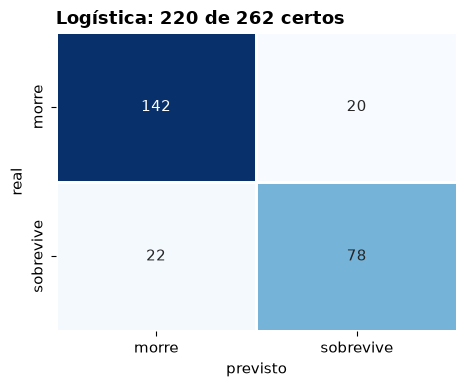

{'threshold': 0.5, 'TP': 78, 'FP': 20, 'FN': 22, 'TN': 142, 'accuracy': 0.84, 'precision': 0.796, 'recall': 0.78, 'f1': 0.788}


In [23]:
c = confusion_at(y_test, probs["Regressão logística"], 0.5)
cm = np.array([[c["TN"], c["FP"]], [c["FN"], c["TP"]]])
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=1,
            xticklabels=["morre", "sobrevive"], yticklabels=["morre", "sobrevive"], ax=ax)
ax.set(xlabel="previsto", ylabel="real", title=f"Logística: {c['TP'] + c['TN']} de {cm.sum()} certos")
ax.grid(False)
fig.tight_layout()
plt.show()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in c.items()})

### 💬 Discussão — Accuracy, precision ou recall?
Com limiar 0,5, a logística tem TP/FP/FN/TN = 78/20/22/142. Descreve em palavras o que significam os 20 FP e os 22 FN. Qual dos dois erros te preocuparia mais num hospital? E num cenário de triagem de salvamento?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Os **20 FP** são pessoas que o modelo diz que sobrevivem mas morreram; os **22 FN** sobrevivem apesar de o modelo prever que morrem. Accuracy 0,840, *precision* 0,796, *recall* 0,780: parecem equilibrados, mas o **custo** não é simétrico. Num hospital a preocupação típica é o **FN** (doente não detetado). No cenário didático de salvamento em que "sobrevive" significa "não precisa de ajuda prioritária", o **FP** é o grave: deixa-se sem ajuda quem precisava. A escolha de métrica e limiar deve ser feita pelo custo de cada erro, não pela métrica mais conhecida.
</details>

### 6.2 Escolher o *threshold* com custos (cenário didático)
O limiar 0,5 é uma convenção, não uma lei. **Cenário (custos escolhidos para o exemplo, não reais):** uma equipa de socorro usa o modelo para decidir quem **não** precisa de ajuda prioritária. Positivo = "sobrevive". Dizer "sobrevive" a quem não sobrevive (**FP**) custa **5**; o contrário (**FN**) custa **1**.

Como escolher o limiar **sem espreitar o teste**? Usamos probabilidades ***out-of-fold***: com `cross_val_predict`, cada passageiro do treino é previsto por um modelo que **não o viu** durante o ajuste. Escolhemos o limiar nessas previsões, e só depois o aplicamos ao teste.

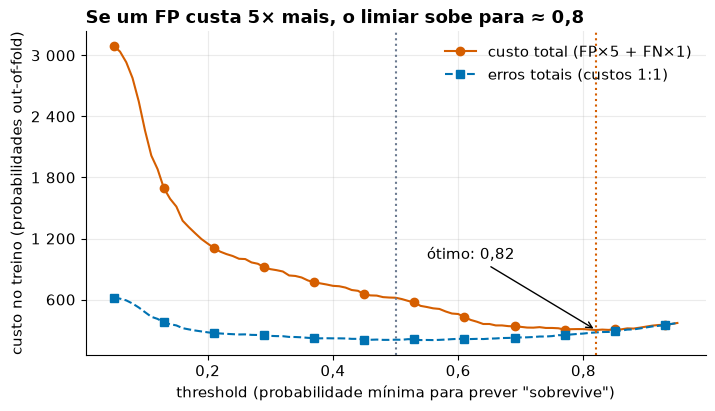

Limiar ótimo (FP=5, FN=1): 0,82 · com custos 1:1: 0,54


In [24]:
oof = cross_val_predict(models["Regressão logística"], X_train, y_train, cv=cv, method="predict_proba")[:, 1]
COST_FP, COST_FN = 5, 1
t_best = best_threshold(y_train, oof, COST_FP, COST_FN)
t_equal = best_threshold(y_train, oof, 1, 1)
tab = threshold_table(y_train, oof, COST_FP, COST_FN)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tab["threshold"], tab["cost"], color=PALETTE["red"], marker="o", markevery=8, label=f"custo total (FP×{COST_FP} + FN×{COST_FN})")
ax.plot(tab["threshold"], tab["FP"] + tab["FN"], color=PALETTE["blue"], ls="--", marker="s", markevery=8, label="erros totais (custos 1:1)")
ax.axvline(t_best, color=PALETTE["red"], ls=":")
ax.axvline(0.5, color=PALETTE["grey"], ls=":")
ax.annotate(f"ótimo: {fmt_pt(t_best, 2)}", (t_best, tab.loc[tab["threshold"] == t_best, "cost"].iloc[0]), xytext=(t_best - 0.27, 1000), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="threshold (probabilidade mínima para prever \"sobrevive\")", ylabel="custo no treino (probabilidades out-of-fold)",
       title="Se um FP custa 5× mais, o limiar sobe para ≈ 0,8")
ax.legend()
pt_axis(ax, "x", 1, 6)
pt_axis(ax, "y", 0, 6)
plt.show()
print(f"Limiar ótimo (FP=5, FN=1): {fmt_pt(t_best, 2)} · com custos 1:1: {fmt_pt(t_equal, 2)}")

In [25]:
p = probs["Regressão logística"]
comp = pd.DataFrame([confusion_at(y_test, p, t) for t in (0.5, t_equal, t_best)], index=["0,50 (convenção)", "custos 1:1", "custos FP=5, FN=1"])
comp["custo no teste"] = comp["FP"] * COST_FP + comp["FN"] * COST_FN
comp[["threshold", "TP", "FP", "FN", "TN", "precision", "recall", "accuracy", "custo no teste"]].round(3)

,threshold,TP,FP,FN,TN,precision,recall,accuracy,custo no teste
"0,50 (convenção)",0.50,78,20,22,142,0.796,0.78,0.840,122
custos 1:1,0.54,76,20,24,142,0.792,0.76,0.832,124
"custos FP=5, FN=1",0.82,39,3,61,159,0.929,0.39,0.756,76


> 💡 **Repara:** o limiar mais alto **baixa a accuracy** (de 0,840 para ≈ 0,756) e o *recall*, mas **reduz o custo** porque quase elimina os FP. A "melhor" accuracy não é o melhor modelo para a **decisão**. Os custos 5:1 são **didáticos**: numa situação real teriam de ser definidos com quem decide e com considerações éticas.

### 💬 Discussão — Quem decide os custos?
Os custos FP=5, FN=1 foram inventados por nós. Quem deveria decidi-los num caso real? O que mudaria se fossem 1:5?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Os custos refletem **valores**, não só técnica: quem decide o que é pior (deixar de ajudar alguém vs. gastar recursos em quem não precisa) deve ser a organização com a responsabilidade, ouvindo os afetados e com enquadramento ético/legal. Se fossem **1:5** (FN mais caro), o limiar desceria bastante abaixo de 0,5: o modelo passaria a dizer "sobrevive" menos vezes e a proteger mais gente à custa de mais falsos alarmes. Note-se também que o limiar ótimo foi escolhido com dados do **treino** (out-of-fold); se o escolhêssemos no teste, estaríamos a "afinar" no cofre e a perder uma estimativa honesta.
</details>

### 6.3 Dois passageiros, duas probabilidades. E a equidade?
Vamos comparar duas pessoas e depois ver se o desempenho do modelo é igual entre **grupos**.

In [26]:
def predict_survival(passenger: dict, model=None) -> float:
    """Probabilidade (0-1) de sobrevivência. Campos: pclass (1-3), sex ('male'/'female'), age (ou None), sibsp, parch,
    fare, embarked ('C','Q','S'), cabin (opcional), title (opcional; é deduzido se faltar)."""
    model = model or fitted["Regressão logística"]
    p = {"pclass": 3, "sex": "male", "age": None, "sibsp": 0, "parch": 0, "fare": 14.5, "embarked": "S", "cabin": None, **passenger}
    if p["sex"] not in ("male", "female") or int(p["pclass"]) not in (1, 2, 3):
        raise ValueError("sex deve ser 'male' ou 'female' e pclass 1, 2 ou 3")
    age = p["age"]
    title = p.get("title") or ("Master" if p["sex"] == "male" and age is not None and age < 13 else "Mr" if p["sex"] == "male"
                               else "Miss" if (age is not None and age < 18) or p["sibsp"] == 0 else "Mrs")
    row = pd.DataFrame([{**p, "name": f"Passageiro, {title}. Anónimo", "age": np.nan if age is None else age}])
    return float(model.predict_proba(add_titanic_features(row)[TITANIC_FEATURES])[0, 1])


mulher_1 = {"pclass": 1, "sex": "female", "age": 30, "fare": 85, "embarked": "C", "cabin": "B20"}
homem_3 = {"pclass": 3, "sex": "male", "age": 30, "fare": 8, "embarked": "S"}
print(f"Mulher, 1.ª classe, 30 anos: {fmt_pt(100 * (predict_survival(mulher_1)), 0)} % · Homem, 3.ª classe, 30 anos: {fmt_pt(100 * (predict_survival(homem_3)), 0)} %")

Mulher, 1.ª classe, 30 anos: 94 % · Homem, 3.ª classe, 30 anos: 9 %


In [27]:
# Desempenho por grupo no teste (limiar 0,5): o modelo erra igual para todos?
pred = (probs["Regressão logística"] >= 0.5).astype(int)
g = X_test.assign(y=y_test.values, pred=pred)
linhas = []
for col in ("sex", "pclass"):
    for val, d in g.groupby(col):
        linhas.append({"grupo": f"{col}={val}", "n": len(d), "sobreviveram (real)": d["y"].mean(), "previsto sobrevive": d["pred"].mean(),
                       "accuracy": accuracy_score(d["y"], d["pred"]), "recall": recall_score(d["y"], d["pred"], zero_division=0)})
pd.DataFrame(linhas).set_index("grupo").round(2)

,n,sobreviveram (real),previsto sobrevive,accuracy,recall
grupo,,,,,
sex=female,94,0.76,0.90,0.83,0.99
sex=male,168,0.17,0.08,0.85,0.28
pclass=1,74,0.62,0.55,0.77,0.76
pclass=2,57,0.46,0.44,0.98,0.96
pclass=3,131,0.21,0.24,0.82,0.64


### 💬 Discussão — O modelo é justo?
O modelo usa sexo e classe, e dá probabilidades muito diferentes a uma mulher de 1.ª classe e a um homem de 3.ª. Isto é um problema? Em que contexto passaria a ser?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

Aqui o modelo **descreve** o que aconteceu em 1912 (quem teve acesso a botes), por isso reproduzir a diferença é o objetivo, **não** um defeito. A questão muda quando um modelo parecido **decide** sobre pessoas hoje (crédito, contratação, triagem): usar sexo ou um *proxy* dele (título, classe) perpetua desigualdades. A tabela por grupo mostra outro ponto: o *recall* e a accuracy **não são iguais** entre grupos (por exemplo, o modelo falha mais a identificar sobreviventes entre os homens e entre a 3.ª classe, onde são minoria). Perguntas a fazer em casos reais: quem é afetado por cada tipo de erro? As métricas por subgrupo são aceitáveis? Há alternativa sem atributos sensíveis? Quem pode contestar uma decisão?
</details>

### ✏️ Exercício 2 — Custos 1:1 e 1:5
**Dificuldade:** ⭐⭐

Repete a escolha de limiar com custos **FP=1, FN=5**: qual é o limiar ótimo no treino (out-of-fold)? Como compara com 0,5 e com o caso FP=5, FN=1? Completa o `TODO`.

In [28]:
# TODO: calcula o limiar ótimo para custos FP=1, FN=5 com best_threshold(y_train, oof, cost_fp, cost_fn)
# e avalia-o no teste com confusion_at(y_test, p, limiar)
print("limiar FP=5,FN=1:", t_best)

limiar FP=5,FN=1: 0.82


<details>
<summary>💡 Ver solução</summary>

```python
t_fn = best_threshold(y_train, oof, 1, 5)
print("limiar FP=1, FN=5:", t_fn, "· limiar FP=5, FN=1:", t_best)
print(confusion_at(y_test, p, t_fn))
```

Quando o FN é o erro caro, o limiar **desce** para ≈ 0,20 (*recall* 0,90 no teste, com mais FP): o modelo aceita mais falsos alarmes para não deixar escapar sobreviventes. Com FP=5 sobe para 0,82. O limiar é uma **decisão de custos**, não uma propriedade do modelo.
</details>

### 6.4 O que pesa no modelo? (*permutation importance*)

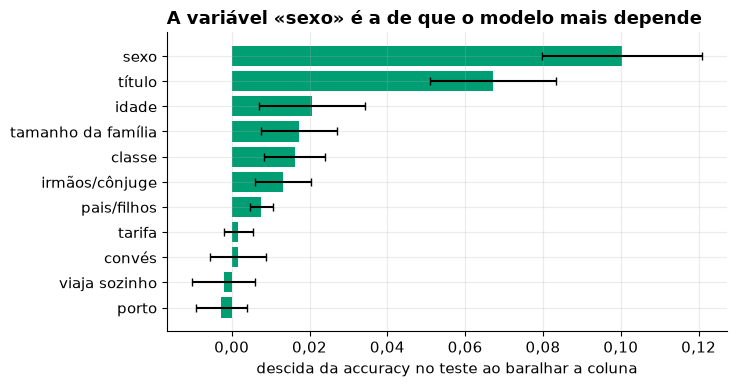

In [29]:
imp = permutation_importance(fitted["Regressão logística"], X_test, y_test, scoring="accuracy", n_repeats=20, random_state=42)
perm = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh([PT_VARS[c] for c in perm.index], perm.values, xerr=pd.Series(imp.importances_std, index=X_test.columns)[perm.index], color=PALETTE["green"], capsize=3)
ax.set(xlabel="descida da accuracy no teste ao baralhar a coluna", title=f"A variável «{PT_VARS[perm.index[-1]]}» é a de que o modelo mais depende")
pt_axis(ax, "x", 2, 6)
ax.xaxis.set_major_locator(MultipleLocator(0.02))
fig.tight_layout()
plt.show()

<a id="sec-7"></a>
# 7. 🚀 Deployment (implementação)

Já definimos `predict_survival(passenger: dict) -> probabilidade`, que recebe um dicionário (campos em falta têm valores por omissão), valida o essencial e usa o *pipeline* completo (imputação + codificação + modelo). Para a "implementação" final, ajustamos a logística a **todos** os passageiros.

In [30]:
final = make_model(LogisticRegression(max_iter=1000)).fit(X, y)
print("Probabilidade, modelo final:", f"mulher 1.ª {fmt_pt(100 * (predict_survival(mulher_1, final)), 0)} % · homem 3.ª {fmt_pt(100 * (predict_survival(homem_3, final)), 0)} %")

Probabilidade, modelo final: mulher 1.ª 95 % · homem 3.ª 8 %


### 🧍 E tu, terias sobrevivido?
Muda os valores e executa. Funciona em qualquer ambiente (também no Colab), sem *widgets*. É **um exercício de curiosidade**, não uma previsão sobre ti: o modelo só conhece 1309 pessoas de 1912.

In [31]:
# 🧍 Os teus dados (altera e volta a executar)
tu = {"pclass": 3, "sex": "female", "age": 25, "sibsp": 0, "parch": 0, "fare": 10, "embarked": "S"}
p_tu = predict_survival(tu, final)
print(f"Probabilidade estimada de sobrevivência: {fmt_pt(100 * (p_tu), 0)} %")
print("→ o modelo diria", "\"sobrevive\"" if p_tu >= 0.5 else "\"não sobrevive\"", "com o limiar 0,5 (e", f"{fmt_pt(100 * (p_tu), 0)} % não é certeza!)")

Probabilidade estimada de sobrevivência: 58 %
→ o modelo diria "sobrevive" com o limiar 0,5 (e 58 % não é certeza!)


<details>
<summary>🎛️ Versão interativa com <code>ipywidgets</code> (opcional)</summary>

Se tiveres `ipywidgets`, podes ligar a mesma função a *sliders* (não é executado aqui para o notebook correr em qualquer lado):

```python
import ipywidgets as w
w.interact(lambda pclass=(1, 3), age=(1, 80), sex=["female", "male"]:
           print(f"{predict_survival({'pclass': pclass, 'age': age, 'sex': sex}, final):.0%}"),
           pclass=(1, 3), age=(1, 80), sex=["female", "male"]);
```
</details>

### Limites, ética e monitorização
- **Dados de 1912:** descrevem decisões num contexto irrepetível. Aplicar o modelo a pessoas de hoje não faz sentido.
- **Amostra e viés:** só inclui passageiros (não a tripulação); idades e classes têm erros de registo (263 idades em falta).
- **Uso responsável:** uma probabilidade **não é um destino**; evitar usar modelos assim para decisões sobre pessoas sem supervisão humana e possibilidade de contestação.
- **Monitorização (se fosse real):** estabilidade da distribuição das entradas, métricas **por subgrupo** e revisão periódica dos custos que definem o limiar.

> 📚 **Extensões:** **calibração** (as probabilidades de 70 % acontecem 70 % das vezes? ver `sklearn.calibration`) e **SHAP** (explicações por passageiro) são os passos naturais seguintes.

### 💬 Discussão — Do notebook para o mundo real
Imagina que este modelo ia ser usado hoje por uma equipa de socorro. Que três mudanças farias antes de o implementar?

<details>
<summary>🧑‍🏫 Resposta-guia para o instrutor</summary>

(1) **Dados**: recolher dados atuais e relevantes; os de 1912 não generalizam. (2) **Variáveis**: remover ou justificar atributos sensíveis e *proxies*, e garantir que todas existem no momento da decisão (sem `boat`/`body`: a accuracy de 0,966 era uma ilusão). (3) **Processo**: custos e limiar definidos com os decisores, avaliação **por subgrupo**, humano no circuito, canal de contestação e monitorização contínua. E ainda: comunicar que a probabilidade tem incerteza, não é uma etiqueta.
</details>

### ✏️ Exercício 3 — Efeito marginal de viajar acompanhado
**Dificuldade:** ⭐

Usa `predict_survival` para comparar a mesma pessoa (mulher, 25 anos, 3.ª classe) viajando sozinha ou com 3 familiares (`sibsp=1`, `parch=2`). O que muda, e porquê pode ser enganador interpretar isto como causal?

In [32]:
sozinha = {"pclass": 3, "sex": "female", "age": 25}
# TODO: cria a variante acompanhada e compara as probabilidades
print(f"sozinha: {fmt_pt(100 * (predict_survival(sozinha, final)), 0)} %")

sozinha: 58 %


<details>
<summary>💡 Ver solução</summary>

```python
sozinha = {"pclass": 3, "sex": "female", "age": 25}
acompanhada = {**sozinha, "sibsp": 1, "parch": 2}
print(f"sozinha: {fmt_pt(100 * (predict_survival(sozinha, final)), 0)} % · acompanhada: {fmt_pt(100 * (predict_survival(acompanhada, final)), 0)} %")
```

A diferença é minúscula (≈ 58 % vs. 57 %): **depois de fixar sexo, classe e idade**, o tamanho da família quase não muda a previsão. E mesmo que mudasse, seria uma **associação** do histórico, não prova de que *viajar acompanhado causa* menos (ou mais) sobrevivência: há confusão com cabine e ordem de embarque.
</details>

<a id="sec-8"></a>
# 8. 📌 Resumo

| Fase CRISP-DM | O que fizemos | Lição |
|---|---|---|
| 🧭 Business Understanding | Contexto histórico, cenário de custos FP=5/FN=1 (didático) | O custo do erro define a métrica |
| 🔎 Data Understanding | Taxas por sexo/classe/idade/família; heatmap classe × sexo; NAs; títulos | Interações e confusão; NAs podem ser informação |
| 🧹 Data Preparation | `add_titanic_features`, `GroupMedianImputer` no *pipeline*, split estratificado | Tudo o que tem `fit` vive no *pipeline* |
| 🚨 Leakage | `has_boat` → 0,966 vs. 0,840 | Resultados bons demais: desconfia |
| 🤖 Modeling | Baseline, logística, RF, HGB; CV estratificada | Empate técnico → escolhe o mais simples |
| 📏 Evaluation | Matriz de confusão, P/R/F1, ROC/PR, limiar por custos (OOF) | O limiar é uma decisão; avaliar por grupos |
| 🚀 Deployment | `predict_survival`, limites, ética | Um modelo descreve o passado; cuidado com decisões sobre pessoas |

**✅ Checklist:**
- [ ] Cada variável estará disponível **no momento da previsão**?
- [ ] Comparei com o *baseline* da classe maioritária?
- [ ] Usei validação estratificada e medi mais do que a accuracy?
- [ ] Escolhi o limiar com **custos** e dados que não são o teste?
- [ ] Olhei para o desempenho **por subgrupo**?
- [ ] Sei quem é afetado se o modelo errar?

<a id="sec-9"></a>
# 9. 📚 Para saber mais

> 📚 **Para saber mais**
> - Chapman et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS / NCR / DaimlerChrysler.
> - scikit-learn User Guide: [Métricas e avaliação](https://scikit-learn.org/stable/modules/model_evaluation.html) · [Ajustar o limiar de decisão](https://scikit-learn.org/stable/modules/classification_threshold.html) · [Validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html) · [*Common pitfalls* (leakage)](https://scikit-learn.org/stable/common_pitfalls.html) · [Calibração de probabilidades](https://scikit-learn.org/stable/modules/calibration.html)
> - Dados `titanic3`: Harrell & Cason, Vanderbilt Biostatistics, <https://hbiostat.org/data/>.
>
> 🤖 **Ligação à IA:** os modelos de linguagem também "dão probabilidades" (da próxima palavra), e a escolha de *threshold*, a avaliação por grupos e o *leakage* (dados de teste vistos no treino) aplicam-se igualmente à sua avaliação.

---
<div align="center">

⬅️ [Anterior: 01 · CRISP-DM: preços de casas](01_CRISP-DM_House_Prices.ipynb) &nbsp;·&nbsp; 🏠 [Lição 02](../../README.md) &nbsp;·&nbsp; [Seguinte: 03 · Aprendizagem não supervisionada](../../02_unsupervised_learning/notebooks/03_Unsupervised_Learning.ipynb) ➡️

**The AI Learning Hub** · Lição 02 — Machine Learning: fundamentos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>